# Default y prepago: PD condicional no es incidencia acumulada
## Resumen
Un motor pequeño conserva población activa y dos salidas competidoras. Datos sintéticos, períodos uniformes y sin afirmación de conformidadIFRS9. El baseline sin prepago representa otro supuesto, no un bug atribuido al repositorio.

## Método y contrato
$S_0=1$, $D_t=S_{t-1}d_t$, $P_t=S_{t-1}p_t$, $S_t=S_{t-1}(1-d_t-p_t)$. Default y prepago son mutuamente excluyentes dado activo, con d+p≤1. No son hazards independientes continuos ni se ordenan artificialmente dentro delperíodo.

$EL=\sum_t D_t EAD_t LGD/(1+r)^t$. EAD condicional no debe incluir ya supervivencia/prepago. Todos los parámetros comparten unidadperíodo; no se divide unaPDanual para obtener mensual automáticamente. Hipótesis preespecificada: baseline superaELconjunta≥20% en caso12períodos.

In [1]:
from pathlib import Path
import csv,json,math
from IPython.display import display,Image
from src.model import project
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
print(json.dumps(metrics,indent=2))
assert metrics['hypothesis_passed']

{
  "config": {
    "periods": 12,
    "conditional_default": 0.02,
    "conditional_prepayment": 0.1,
    "conditional_ead": 100,
    "lgd": 0.45,
    "period_discount_rate": 0.005,
    "prepayment_grid": [
      0,
      0.02,
      0.05,
      0.1,
      0.2
    ],
    "hypothesis": "ignoring competing prepayment overstates expected loss by>=20% relative to joint-exit model",
    "data": "synthetic probabilities, not estimated borrower hazards"
  },
  "baseline_expected_loss": 9.391360600405692,
  "joint_expected_loss": 5.737378944381399,
  "baseline_default_probability": 0.21528327626519994,
  "joint_default_probability": 0.13072147402971984,
  "relative_baseline_overstatement": 0.6368729852858381,
  "rational_oracle_loss": 5.737378944381397,
  "rational_oracle_error": 2.6645352591003757e-15,
  "hypothesis_passed": true,
  "seconds": 0.002561017999937576,
  "peak_tracemalloc_bytes": 17345,
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "platform": "Linux-6.1

## Datos y resultados
12períodos,d=.02,p=.10,EAD100,LGD.45,r=.005. Baseline cambia solo prepago a0. Comparación determinista y oráculo racional independiente; no incertidumbre estadística estimada ni parámetros reales.

{'conditional_prepayment': '0', 'default_probability': '0.21528327626519994', 'prepayment_probability': '0.0', 'active_probability': '0.7847167237347998', 'expected_loss': '9.391360600405692', 'mass_error': '2.220446049250313e-16'}
{'conditional_prepayment': '0.02', 'default_probability': '0.1936451213351163', 'prepayment_probability': '0.1936451213351163', 'active_probability': '0.6127097573297672', 'expected_loss': '8.457708158113672', 'mass_error': '2.220446049250313e-16'}
{'conditional_prepayment': '0.05', 'default_probability': '0.16611534357732263', 'prepayment_probability': '0.41528835894330657', 'active_probability': '0.4185962974793704', 'expected_loss': '7.268662946877575', 'mass_error': '4.440892098500626e-16'}
{'conditional_prepayment': '0.1', 'default_probability': '0.13072147402971984', 'prepayment_probability': '0.6536073701485992', 'active_probability': '0.215671155821681', 'expected_loss': '5.737378944381399', 'mass_error': '0.0'}
{'conditional_prepayment': '0.2', 'def

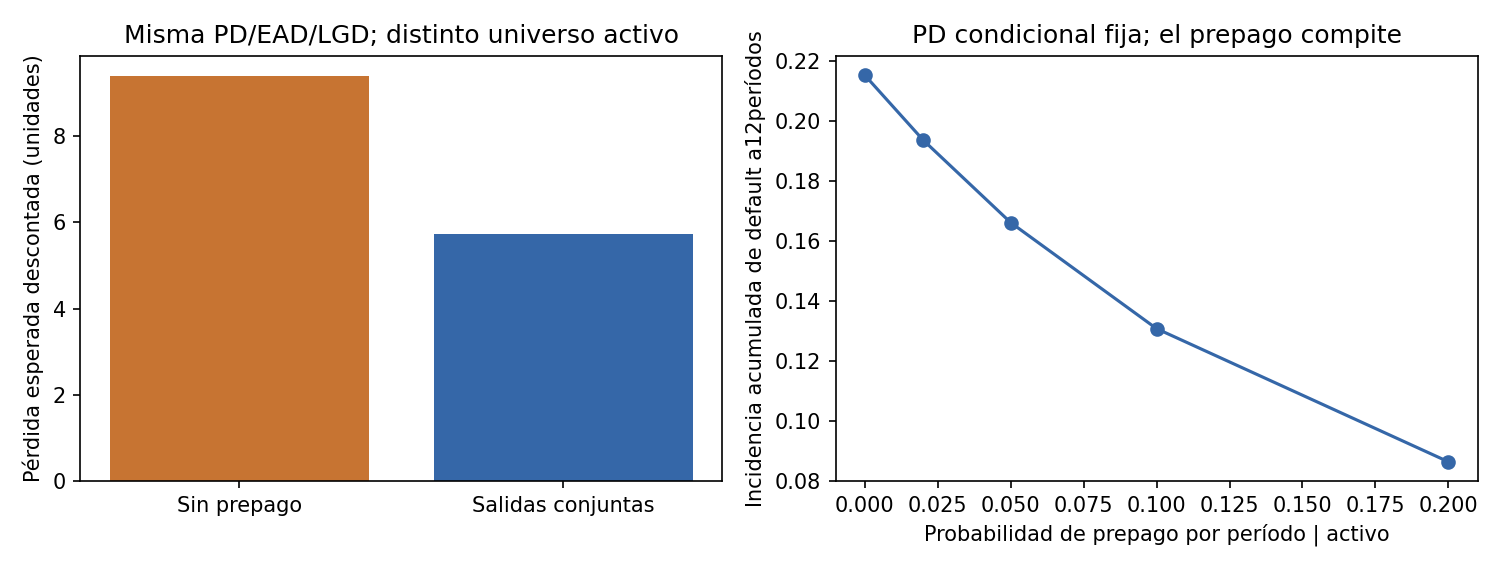

In [2]:
display(Image(filename=str(root/'results/audit.png')))
for row in csv.DictReader((root/'results/sensitivity.csv').open()):print(row)
rows=list(csv.DictReader((root/'results/joint_periods.csv').open()))
print('Primero:',rows[0],'Último:',rows[-1])

## Comprobaciones y casos negativos
Sin prepago,1−S reproducePDlifetime. H1 no presenta diferencia deEL bajo esta convención: no se ha eliminado población antes del primerdefault. Absorción y masa impiden sumar PDcondicionales como si fueran masas marginales.

In [3]:
r=project([.02]*12,[.10]*12,[100.]*12)
assert abs(r.default_probability+r.prepayment_probability+r.active_probability-1)<1e-12
assert abs(project([.02]*12,[0.]*12,[100.]*12).default_probability-(1-.98**12))<1e-12
assert project([.02],[.10],[100.]).expected_loss==project([.02],[0.],[100.]).expected_loss
assert metrics['rational_oracle_error']<1e-12
print('Mass/oracle/negative checks passed')

Mass/oracle/negative checks passed


## Interpretación y límites
El efecto mantiene PDcondicional yEAD fijas; no modela selección de prepago o riesgo de los sobrevivientes. EAD ya ponderada por salidas duplica ajuste y viola elcontrato. Faltan datos,censura,estimación,recobros,staging y reglas de provisión. La cifra no recomienda disminuir provisiones reales. Cinco referencias primarias verificadas e informe14p separan método de alcanceoperacional. Próxima iteración: contrato de calendario yEADantes de integración.